In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# *Heavy Equipment Price Prediction*

This notebook presents an end-to-end machine learning pipeline developed to predict the resale value of industrial equipment using historical transaction and asset information. The project includes data exploration, preprocessing, feature engineering, model development, hyperparameter tuning, and ensemble learning to improve prediction accuracy.

Several regression algorithms, including Linear Regression, Random Forest, CatBoost, LightGBM, HistGradientBoosting, and XGBoost, are trained and evaluated. Model performance is assessed using Root Mean Squared Logarithmic Error (RMSLE), the official evaluation metric for the Kaggle competition. Finally, ensemble techniques are explored to combine the strengths of multiple models and obtain the best predictive performance.

**Objectives**
1. Explore and understand the dataset through exploratory data analysis (EDA).
2. Preprocess missing values and categorical features.
3. Engineer additional features to improve model performance.
4. Train and compare multiple regression models.
5. Evaluate models using RMSLE.
6. Develop ensemble models to improve predictive accuracy.
7. Generate predictions for submission to the Kaggle competition.

In [2]:
md = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')
train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
sample_submission = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

/tmp/ipykernel_16/3702063122.py:2: DtypeWarning: Columns (38,39) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')


**Renaming Column names according to the metadata file for clarity**

In [3]:
# Rename unnamed specification columns using the provided metadata

column_mapping = {
    "col1": "DriveSystemConfiguration",
    "col3": "MachineStabilizationSystem",
    "col4": "ExtensionArmLayout",
    "col5": "EngineAspirationSystem",
    "col6": "PrimaryExtensionModule",
    "col7": "WorkingComponentWidth",
    "col8": "ProtectiveHousing",
    "col9": "EnginePowerOutput",
    "col10": "HydraulicSystemType",
    "col11": "LoadBearingInterface",
    "col12": "PiercingAccessory",
    "col13": "FinishingAccessory",
    "col14": "ActuatorControlSystem",
    "col15": "WheelOrTireDimensions",
    "col16": "CouplingMechanism",
    "col18": "TractionSystem",
    "col19": "HydraulicFlowRate",
    "col20": "TractionTreadPattern",
    "col21": "GroundContactWidth",
    "col22": "OperationalArmReach",
    "col23": "MaterialRetentionInterface",
    "col24": "ControlSystemConfiguration",
    "col25": "TractionComponentProfile",
    "col27": "WorkToolCategory",
    "col28": "SteeringConfiguration",
    "col29": "DifferentialType",
    "col30": "SteeringInterface"
}


train.rename(columns=column_mapping, inplace=True)
test.rename(columns=column_mapping, inplace=True)



print(train.columns.tolist())

['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID', 'DataOriginCode', 'VendorPartnerID', 'ManufactureYear', 'OperationalHoursMeter', 'UtilizationTier', 'TransactionDate', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'DriveSystemConfiguration', 'CabinType', 'Forks', 'MachineStabilizationSystem', 'ExtensionArmLayout', 'DrivetrainType', 'EngineAspirationSystem', 'PrimaryExtensionModule', 'WorkingComponentWidth', 'ProtectiveHousing', 'EnginePowerOutput', 'HydraulicSystemType', 'LoadBearingInterface', 'PiercingAccessory', 'FinishingAccessory', 'ActuatorControlSystem', 'WheelOrTireDimensions', 'CouplingMechanism', 'TractionSystem', 'HydraulicFlowRate', 'TractionTreadPattern', 'GroundContactWidth', 'OperationalArmReach', 'MaterialRetentionInterface', 'ControlSystemConfiguration', 'TractionComponentProfile', '

# Exploratory Data Analysis



**Conclusions from the Initial Dataset Inspection**

* The training dataset contains 138,701 records with 50 columns, while the test dataset contains 15,000 records with 49 columns. The missing column in the test set is the target variable (TargetValue), which is expected for a supervised learning task.
* The dataset is predominantly categorical, with 44 categorical features, 4 integer features, and 2 floating-point features. This indicates that the chosen models and preprocessing pipeline must effectively handle categorical variables.
* Several features contain a very high proportion of missing values. Some columns (such as col18 and col19) are missing in almost every record, while many others also have substantial missingness. Appropriate missing-value handling is therefore an important part of preprocessing.
* The target variable has a wide range of values, from 7,500 to 142,000, with a mean of approximately 41,522. The large spread suggests that models should be robust to varying target magnitudes, which supports the later decision to apply a logarithmic transformation and evaluate using RMSLE.
* No duplicate rows were found in the training dataset, indicating that duplicate removal was not required.

In [4]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nData types:")
print(train.dtypes.value_counts())

print("\nMissing values (Top 20):")
print(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nTarget summary:")
print(train["TargetValue"].describe())

print("\nDuplicate rows:", train.duplicated().sum())

Train shape: (138701, 50)
Test shape: (15000, 49)

Data types:
object     44
int64       4
float64     2
Name: count, dtype: int64

Missing values (Top 20):
HydraulicFlowRate             138635
TractionSystem                138635
EngineAspirationSystem        128320
ExtensionArmLayout            128320
WorkToolCategory              123742
SteeringConfiguration         123742
DifferentialType              119829
SteeringInterface             119829
FinishingAccessory            115296
ActuatorControlSystem         115296
WorkingComponentWidth         115296
PrimaryExtensionModule        115296
EnginePowerOutput             115296
ProtectiveHousing             115296
LoadBearingInterface          115296
MachineStabilizationSystem    109448
Forks                         109382
Spec_ReleaseSeries            105805
DriveSystemConfiguration      104915
PiercingAccessory             100337
dtype: int64

Target summary:
count    138701.000000
mean      41521.874047
std       26361.125948
min 

**Visualising the Target Variable**

1. We can see Target Variable is heavily right skewed. Applying a log transformation is necessary in this case because of:
   > Reduction of skewness
   > Evaluation metric is also logarimthmic
   > Log transformation gives us a more symmetric distribution, closer to a bell curve, which can reduce the range of values, and easier learning for models.
   > We have also compared the TargetValue with individual Features in Bivariate Analysis. Boxplots for the same are given below.

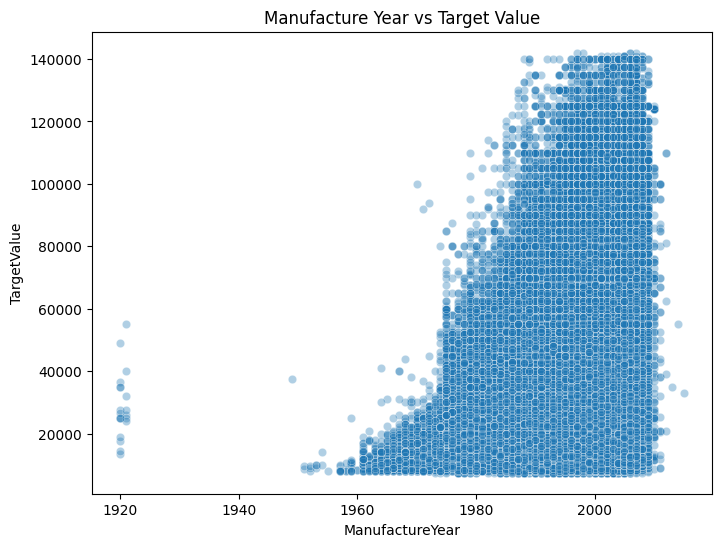

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plot_data = train[train["ManufactureYear"] > 1900]

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=plot_data,
    x="ManufactureYear",
    y="TargetValue",
    alpha=0.35
)

plt.title("Manufacture Year vs Target Value")
plt.show()

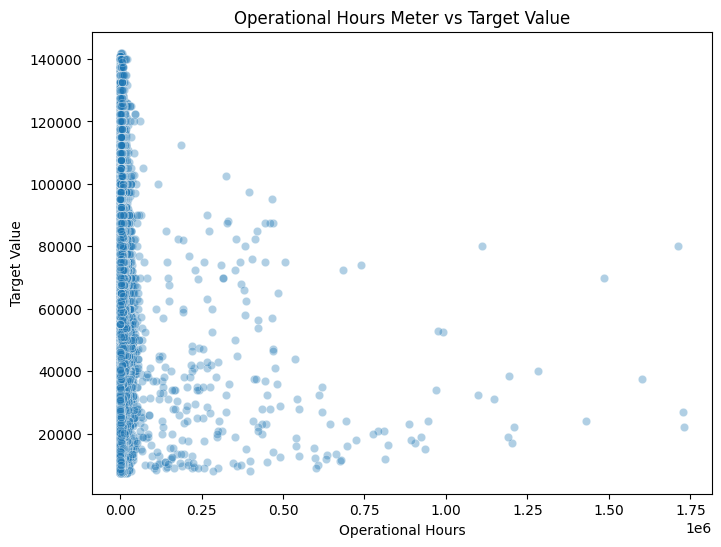

In [6]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=train,
    x="OperationalHoursMeter",
    y="TargetValue",
    alpha=0.35
)

plt.title("Operational Hours Meter vs Target Value")
plt.xlabel("Operational Hours")
plt.ylabel("Target Value")
plt.show()

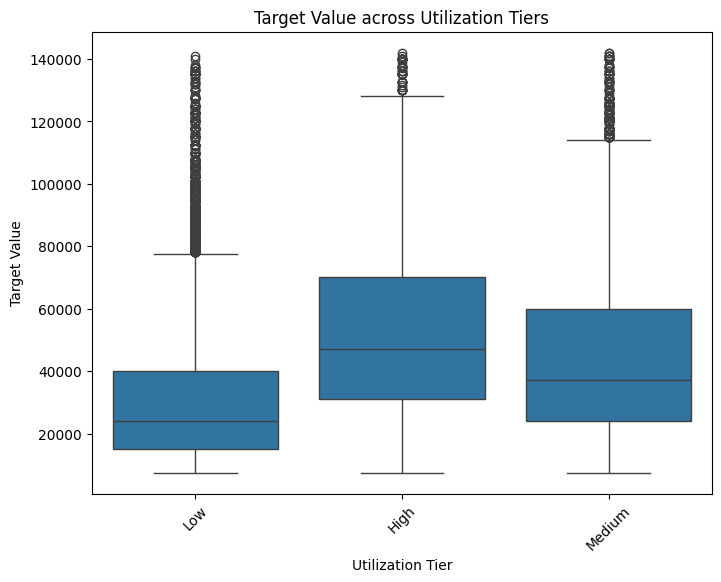

In [7]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=train,
    x="UtilizationTier",
    y="TargetValue"
)

plt.title("Target Value across Utilization Tiers")
plt.xlabel("Utilization Tier")
plt.ylabel("Target Value")
plt.xticks(rotation=45)
plt.show()

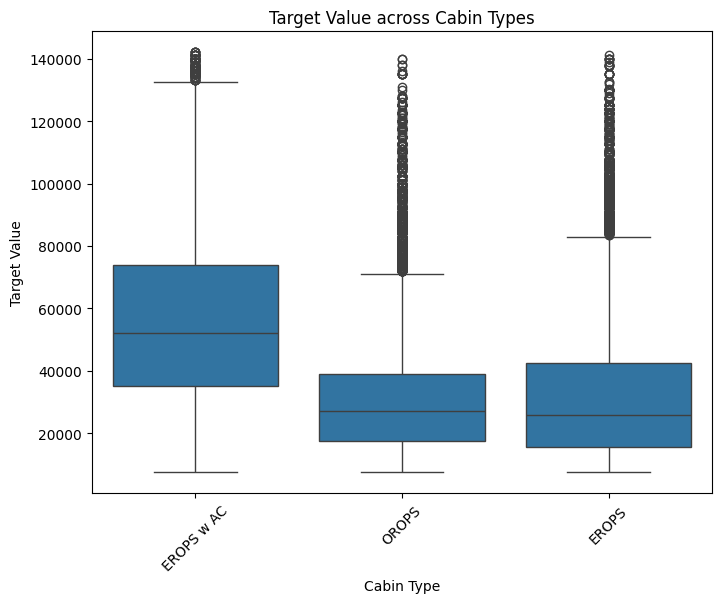

In [8]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=train,
    x="CabinType",
    y="TargetValue"
)

plt.title("Target Value across Cabin Types")
plt.xlabel("Cabin Type")
plt.ylabel("Target Value")
plt.xticks(rotation=45)
plt.show()

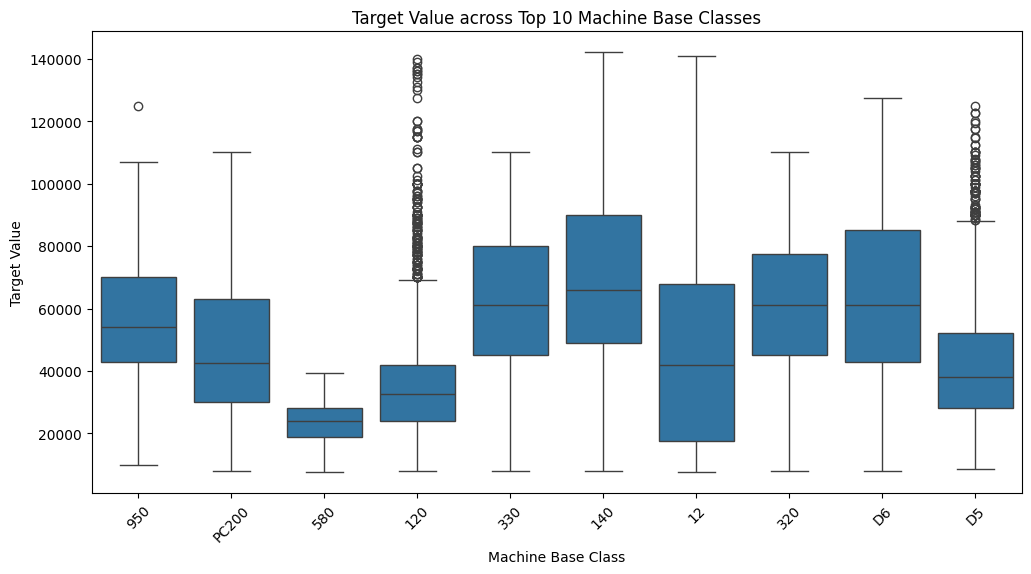

In [9]:
top_classes = train["Spec_BaseClass"].value_counts().nlargest(10).index
plt.figure(figsize=(12,6))
sns.boxplot(data=train[train["Spec_BaseClass"].isin(top_classes)],x="Spec_BaseClass",y="TargetValue")

plt.title("Target Value across Top 10 Machine Base Classes")
plt.xlabel("Machine Base Class")
plt.ylabel("Target Value")
plt.xticks(rotation=45)
plt.show()

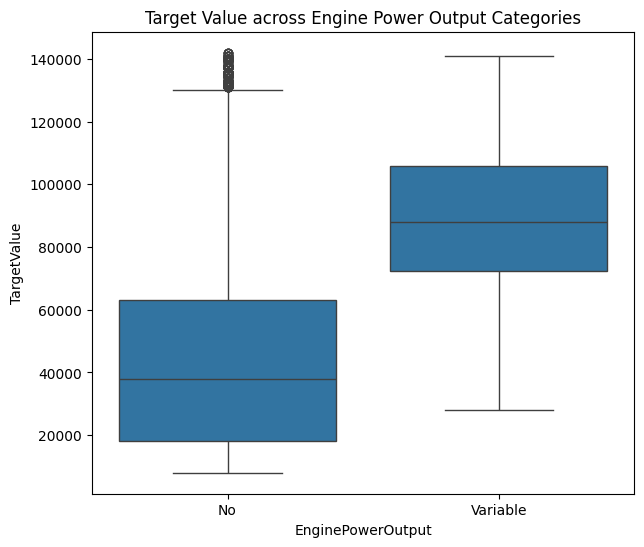

In [10]:
plt.figure(figsize=(7,6))

sns.boxplot(
    data=train,
    x="EnginePowerOutput",
    y="TargetValue"
)

plt.title("Target Value across Engine Power Output Categories")
plt.show()

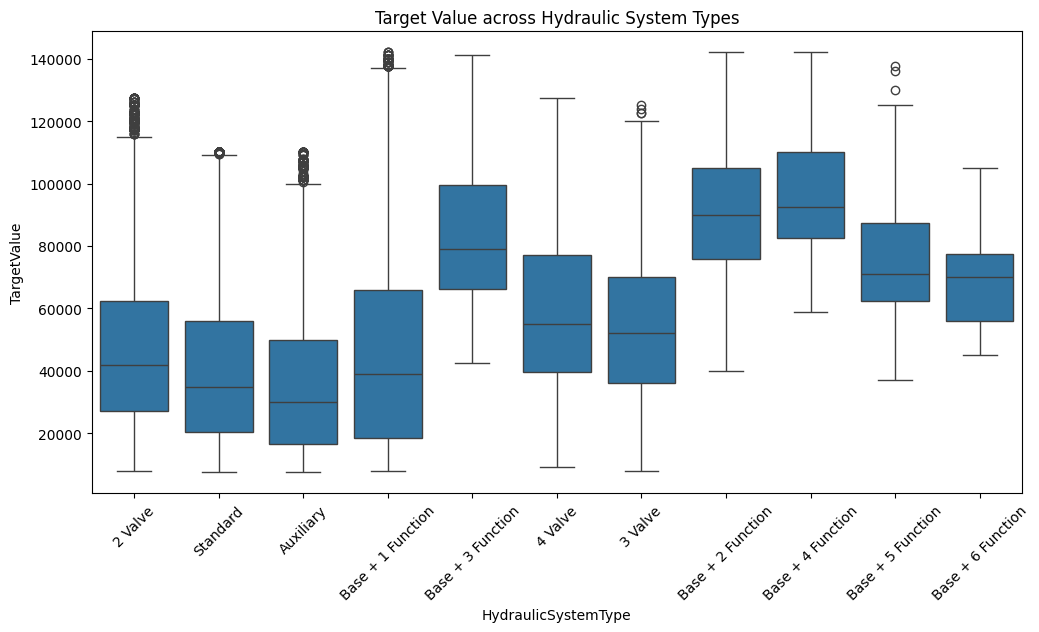

In [11]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=train,
    x="HydraulicSystemType",
    y="TargetValue"
)

plt.xticks(rotation=45)
plt.title("Target Value across Hydraulic System Types")
plt.show()

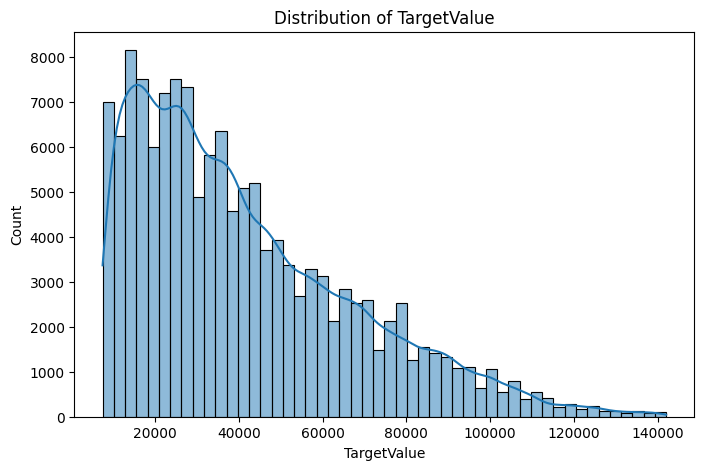

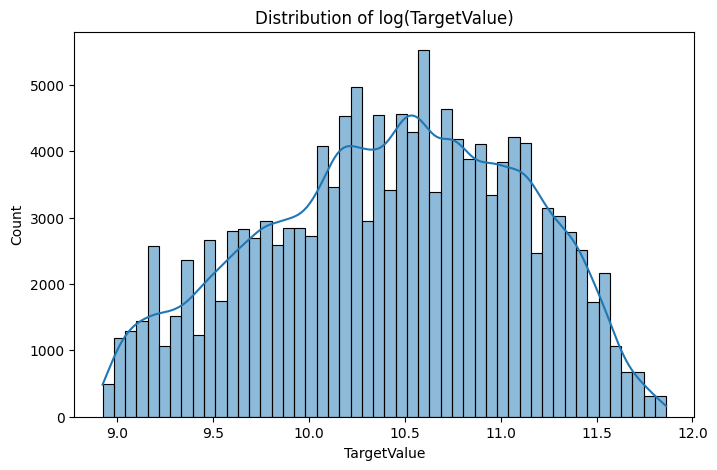

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(8,5))
sns.histplot(train["TargetValue"], bins=50, kde=True)
plt.title("Distribution of TargetValue")
plt.show()

plt.figure(figsize=(8,5))
sns.histplot(np.log1p(train["TargetValue"]), bins=50, kde=True)
plt.title("Distribution of log(TargetValue)")
plt.show()

**Identifying Numerical Values**

1. Helps us identify
   >Missing values
   >Outliers
   >Anomalies
2. Anomalies include, for example, ManufacturingYear having the value of 1001, OperationalHoursMeter has extreme max value, etc, suggesting need for further preprocessing
   

In [13]:
#Identifying numerical columns

# Numerical columns
num_cols = train.select_dtypes(include=["number"]).columns

print(num_cols)

train[num_cols].describe().T

Index(['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID',
       'ManufactureYear', 'OperationalHoursMeter'],
      dtype='object')


,count,mean,std,min,25%,50%,75%,max
TransactionID,138701.0,2.186276e+06,1.128497e+06,1139309.0,1465754.0,1751884.0,2372139.0,6333410.0
TargetValue,138701.0,4.152187e+04,2.636113e+04,7500.0,20500.0,35000.0,57000.0,142000.0
AssetID,138701.0,1.204814e+06,5.287376e+05,8.0,1007930.0,1246956.0,1495817.0,2478476.0
ProductConfigID,138701.0,7.286422e+03,7.542422e+03,39.0,1693.0,3852.0,11873.0,37209.0
ManufactureYear,138701.0,1.891641e+03,3.069920e+02,1001.0,1990.0,1998.0,2004.0,2015.0
OperationalHoursMeter,82058.0,4.553719e+03,2.792204e+04,0.0,0.0,1620.0,5001.0,1729600.0


**Checking Cardinality of Categorical Variables**

Here we check the number of unique values for each categorical variable.
Cardinality is important because it directly affects later preprocessing techniques like encoding.
For example, one hot encoding for high cardinality features can greatly increase dimensionality of the training dataset, directly affecting training time for any model.

In [14]:
#Categorical Variables EDA

cat_cols = train.select_dtypes(include="object").columns

cardinality = (
    train[cat_cols]
    .nunique()
    .sort_values(ascending=False)
)

print(cardinality)

TransactionDate               3676
Spec_FullDescriptor           3505
Spec_BaseClass                1249
Spec_SubClass                  147
Spec_VariantModifier           132
Spec_ReleaseSeries             113
FunctionalClassification        65
RegionCode                      53
VendorPartnerID                 31
OperationalArmReach             27
GroundContactWidth              18
WheelOrTireDimensions           15
HydraulicSystemType             11
WorkToolCategory                 9
DrivetrainType                   8
DataOriginCode                   6
WorkingComponentWidth            6
AssetScaleFactor                 6
InventoryGroupDescription        6
InventoryGroupCategory           6
SteeringConfiguration            5
DriveSystemConfiguration         4
PiercingAccessory                4
UtilizationTier                  3
MachineStabilizationSystem       3
ProtectiveHousing                3
MaterialRetentionInterface       3
CabinType                        3
TractionComponentPro


# Feature Engineering


Feature Engineering

The original dataset was used#  to create a few additional features that were tested to see if they improved the model's performance.

The TransactionDate column was split into year, month, quarter and weekday to check whether any of these components affected the prediction.


AssetAge was calculated to represent the age of the equipment at the time of sale.


DescriptorLength stores the length of the equipment description as a numerical feature.


HasOperationalHours and HasVariantModifier are binary features that indicate whether these values are present or missing, allowing the model to distinguish between available and unavailable information.


MissingValueCount records the total number of missing values in each row to determine whether the overall amount of missing data has any impact on the prediction.



In [15]:
#Defining functions that can be reused for different pipelines

def create_features(df):
    df = df.copy()

    df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

    df["TransactionYear"] = df["TransactionDate"].dt.year
    df["TransactionMonth"] = df["TransactionDate"].dt.month
    df["TransactionQuarter"] = df["TransactionDate"].dt.quarter
    df["TransactionWeekday"] = df["TransactionDate"].dt.dayofweek

    df["AssetAge"] = (
        df["TransactionYear"] -
        df["ManufactureYear"]
    )

    df["DescriptorLength"] = (
        df["Spec_FullDescriptor"]
        .fillna("")
        .str.len()
    )

    df["HasOperationalHours"] = (
        df["OperationalHoursMeter"]
        .notna()
        .astype(int)
    )

    df["HasVariantModifier"] = (
        df["Spec_VariantModifier"]
        .notna()
        .astype(int)
    )

    df["MissingValueCount"] = df.isnull().sum(axis=1)

    return df

In [16]:
train = create_features(train)
test = create_features(test)
print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.info()

Train shape: (138701, 59)
Test shape: (15000, 58)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 59 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   TransactionID               138701 non-null  int64         
 1   TargetValue                 138701 non-null  float64       
 2   AssetID                     138701 non-null  int64         
 3   ProductConfigID             138701 non-null  int64         
 4   DataOriginCode              138701 non-null  object        
 5   VendorPartnerID             138701 non-null  object        
 6   ManufactureYear             138701 non-null  int64         
 7   OperationalHoursMeter       82058 non-null   float64       
 8   UtilizationTier             50475 non-null   object        
 9   TransactionDate             138701 non-null  datetime64[ns]
 10  Spec_FullDescriptor         138701 non-null  object   

In [17]:
#Drop identifiers and original date features after feature engineering

train = train.drop(columns=["TransactionID", "TransactionDate"])
test = test.drop(columns=["TransactionID", "TransactionDate"])

print(train.shape)
print(test.shape)

(138701, 57)
(15000, 56)


**Additional Feature Engineering**

The following features were created to capture equipment usage more effectively and to test whether they improve performance.

HoursPerYear gives the average annual usage of a machine by dividing operational hours by its age.

LogOperationalHours uses a logarithmic transformation because of extremely high operational hour values.

AgeHoursInteraction combines asset age and operational hours to capture the relationship between how old a machine is and how heavily it has been used.

In [18]:
train["HoursPerYear"] = (train["OperationalHoursMeter"]/(train["AssetAge"].clip(lower=0) + 1))

test["HoursPerYear"] = (test["OperationalHoursMeter"]/(test["AssetAge"].clip(lower=0) + 1))


# 2. Log-transformed operational hours
train["LogOperationalHours"] = np.log1p(train["OperationalHoursMeter"].clip(lower=0))

test["LogOperationalHours"] = np.log1p(test["OperationalHoursMeter"].clip(lower=0))


# 3. Interaction between asset age and usage
train["AgeHoursInteraction"] = (train["AssetAge"] * train["LogOperationalHours"])

test["AgeHoursInteraction"] = (test["AssetAge"] * test["LogOperationalHours"])

In [19]:
#Split Data into Features and Target

X = train.drop(columns=["TargetValue"])
y = train["TargetValue"]

print(X.shape)
print(y.shape)

(138701, 59)
(138701,)


**Separating Numerical and Categorical Features**

We separate numerical and categorical features because the preprocessing for each is different. Numerical features will be scaled, and categorical features will be encoded.

A final check is also included to see if there are any features accidentally missing from either.

In [20]:
#Split into training and validation datasets

from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(X,y,test_size=0.2,random_state=42)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (110960, 59)
X_valid: (27741, 59)
y_train: (110960,)
y_valid: (27741,)


In [21]:
numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# **Model Training**

# **1. CatBoost**

>Performs well on tabular data, with multiple categorical features.


**Preparing Data for CatBoost**

Before training, categorical features are converted to strings and missing values are replaced with a placeholder category. 

The indices of all categorical features are then identified so that CatBoost can correctly process them during training.

In [22]:
# ==========================================
# Creating data for CatBoost
# ==========================================

# Create separate copies
X_train_cb = X_train.copy()
X_valid_cb = X_valid.copy()

# Identify categorical columns
cat_cols_cb = X_train_cb.select_dtypes(include=["object", "category"]).columns.tolist()

# Convert categorical columns to strings and fill missing values
for col in cat_cols_cb:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_valid_cb[col] = X_valid_cb[col].fillna("Missing").astype(str)

# Get categorical feature indices for CatBoost
cat_features_indices = [X_train_cb.columns.get_loc(col)for col in cat_cols_cb]

print("X_train_cb shape:", X_train_cb.shape)
print("X_valid_cb shape:", X_valid_cb.shape)

print("Number of categorical features:", len(cat_cols_cb))
print("Number of numerical features:",
      X_train_cb.shape[1] - len(cat_cols_cb))

print("Total features:", X_train_cb.shape[1])

X_train_cb shape: (110960, 59)
X_valid_cb shape: (27741, 59)
Number of categorical features: 43
Number of numerical features: 16
Total features: 59


In [23]:
# Get indices of categorical columns
cat_features = [
    X_train_cb.columns.get_loc(col)
    for col in cat_cols_cb
]

print("Number of categorical features:", len(cat_features))
print(cat_features[:10])   # Show first 10 indices

Number of categorical features: 43
[2, 3, 6, 7, 8, 9, 10, 11, 12, 13]


The target variable is transformed using log1p() before training. This reduces the effect of extreme values, makes the target distribution less skewed, and aligns the training process with the RMSLE evaluation metric. Predictions are converted back to their original scale using expm1() after model prediction.

In [24]:
#Log transform the target variable 

import numpy as np

y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

**Training the CatBoost Model**

The CatBoost model is trained using the prepared training data and the log-transformed target variable. The categorical feature indices are supplied during training so that CatBoost can correctly identify and process categorical features before making predictions.

Hyperparameters such as iterations, learning rate and depth were adjusted for better results of RMSLE.

During manual experimentation, increasing the number of iterations and changing the learning rate did not produce a noticeable improvement in validation RMSLE. The final parameter values were therefore chosen based on the best overall validation performance.

Early stopping is used to prevent overfitting. Training stops automatically if validation score does not improve for 100 consecutive iterations.

In [25]:
#Train model using Catboost

from catboost import CatBoostRegressor

cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=8,
    loss_function="RMSE",
    eval_metric="RMSE",
    random_seed=42,
    verbose=100
)

cat_model.fit(
    X_train_cb,
    y_train_log,
    cat_features=cat_features,
    eval_set=(X_valid_cb, y_valid_log),
    use_best_model=True,
    early_stopping_rounds=100
)

0:	learn: 0.6274411	test: 0.6257352	best: 0.6257352 (0)	total: 913ms	remaining: 15m 12s
100:	learn: 0.2467908	test: 0.2408155	best: 0.2408155 (100)	total: 1m 26s	remaining: 12m 51s
200:	learn: 0.2281457	test: 0.2258595	best: 0.2258595 (200)	total: 2m 56s	remaining: 11m 40s
300:	learn: 0.2189072	test: 0.2195521	best: 0.2195521 (300)	total: 4m 26s	remaining: 10m 19s
400:	learn: 0.2127694	test: 0.2159356	best: 0.2159356 (400)	total: 5m 57s	remaining: 8m 53s
500:	learn: 0.2082975	test: 0.2136961	best: 0.2136961 (500)	total: 7m 27s	remaining: 7m 25s
600:	learn: 0.2047782	test: 0.2122024	best: 0.2122024 (600)	total: 8m 57s	remaining: 5m 57s
700:	learn: 0.2018893	test: 0.2110080	best: 0.2110080 (700)	total: 10m 26s	remaining: 4m 27s
800:	learn: 0.1993215	test: 0.2101539	best: 0.2101539 (800)	total: 11m 56s	remaining: 2m 57s
900:	learn: 0.1966260	test: 0.2092566	best: 0.2092566 (900)	total: 13m 27s	remaining: 1m 28s
999:	learn: 0.1945259	test: 0.2086501	best: 0.2086487 (998)	total: 14m 56s	rem

CatBoostRegressor(depth=8, eval_metric='RMSE', iterations=1000, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=100)

**Generating Predictions**

Predictions are first generated in the log-transformed space and then converted back to the original target scale using expm1(). 

Any negative predicted values are clipped to zero using np.maximum(), as the target variable cannot take negative values.

In [26]:
# Predict in log space
y_pred_log = cat_model.predict(X_valid_cb)

# Convert back to original scale
y_pred_cb = np.expm1(y_pred_log)

# Ensure no negative values
y_pred_cb = np.maximum(y_pred_cb, 0)

**Model Evaluation**

In [27]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_log_error
)

print("RMSLE CB  :", root_mean_squared_log_error(y_valid, y_pred_cb))

RMSLE CB  : 0.20864872505425716


# 2. LightGBM

>Trains efficiently on large datasets which include both numerical and categorical features. Optimized for speed.

**Preparing Data for LightGBM**

Separate copies of the training and validation datasets are created for LightGBM preprocessing. The categorical features are identified and converted to the category data type. The validation dataset is then aligned with the training dataset by assigning the same category levels to each categorical feature. This ensures that LightGBM processes categorical variables consistently during training and validation.

In [28]:
from sklearn.impute import SimpleImputer

# Make LGB copies
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()

# Get numerical columns
numerical_cols_lgb = X_train_lgb.select_dtypes(
    include=["number"]
).columns.tolist()

# Fresh imputer
imputer_lgb = SimpleImputer(strategy="median")

# Fit on training data
X_train_lgb[numerical_cols_lgb] = imputer_lgb.fit_transform(
    X_train_lgb[numerical_cols_lgb]
)

# Apply same imputer to validation data
X_valid_lgb[numerical_cols_lgb] = imputer_lgb.transform(
    X_valid_lgb[numerical_cols_lgb]
)

In [29]:
# Identify categorical columns
cat_cols_lgb = X_train_lgb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Convert categorical columns
for col in cat_cols_lgb:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    X_valid_lgb[col] = X_valid_lgb[col].astype("category")

**Training the LightGBM Model**

The LightGBM regressor is configured using manually selected hyperparameters. 

During experimentation, parameters such as the number of estimators (n_estimators), the maximum number of leaves (num_leaves), and the fraction of features considered during training (feature_fraction) were adjusted and evaluated using the validation set. 

The final configuration was chosen based on its validation RMSLE performance.

In [30]:
#Create LGB model
from lightgbm import LGBMRegressor

lgb_model = LGBMRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=127,
    feature_fraction=0.8,
    random_state=42,
    verbose=-1
)

In [31]:
#Train using LGB

from lightgbm import early_stopping

lgb_model.fit(
    X_train_lgb,
    y_train_log,
    eval_set=[(X_valid_lgb, y_valid_log)],
    eval_metric="rmse",
    callbacks=[
        early_stopping(stopping_rounds=100)
    ]
)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[2652]	valid_0's rmse: 0.200846	valid_0's l2: 0.0403391


LGBMRegressor(feature_fraction=0.8, learning_rate=0.05, max_depth=8,
              n_estimators=3000, num_leaves=127, random_state=42, verbose=-1)

# 2.1 Hyperparameter Training for LGBM

In [32]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMRegressor
from scipy.stats import randint, uniform

# Base LightGBM model
RCVlgb_model = LGBMRegressor(
    random_state=42,
    verbose=-1
)

# Parameter search space
param_dist = {
    "n_estimators": randint(200, 700),
    "learning_rate": uniform(0.01, 0.09),      # 0.01 - 0.10
    "num_leaves": randint(20, 120),
    "max_depth": [-1, 5, 10, 15, 20],
    "min_child_samples": randint(10, 60),
    "subsample": uniform(0.7, 0.3),            # 0.7 - 1.0
    "colsample_bytree": uniform(0.7, 0.3)
}

random_search = RandomizedSearchCV(
    estimator=RCVlgb_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(
    X_train_lgb,
    y_train_log,
    categorical_feature=cat_cols_lgb
)

best_lgb = random_search.best_estimator_

print(random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
{'colsample_bytree': np.float64(0.9687290787020557), 'learning_rate': np.float64(0.052783320086390056), 'max_depth': 20, 'min_child_samples': 41, 'n_estimators': 587, 'num_leaves': 113, 'subsample': np.float64(0.7417994363217627)}


In [33]:
#Predict using trained model

from sklearn.metrics import ( r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_log_error )
y_pred_log = lgb_model.predict(X_valid_lgb)

y_pred_lgb = np.expm1(y_pred_log)

y_pred_lgb = np.maximum(y_pred_lgb, 0)
#Evaluation Metrics
print("RMSLE LGB    :", root_mean_squared_log_error(y_valid, y_pred_lgb))

RMSLE LGB    : 0.2008458822168687


In [34]:
# Predict using RCV tuned model
y_pred_log = best_lgb.predict(X_valid_lgb)

# Convert back to original scale
y_pred = np.expm1(y_pred_log)

# Evaluate on original target
rmsle = root_mean_squared_log_error(y_valid, y_pred)

print("Validation RMSLE:", rmsle)

Validation RMSLE: 0.20353800171714093


# 2.2 Comparison of Manually Tuned vs RandomizedSearchCV Model Scores for LightGBM

In [35]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "LightGBM (Manual + Early Stopping)",
        "LightGBM (RandomizedSearchCV)"
    ],
    "Validation RMSLE": [
        0.2008458822168687,
        0.20353800171714093
    ]
})

comparison_df["Improvement vs Manual"] = (
    comparison_df["Validation RMSLE"] -
    comparison_df["Validation RMSLE"].min()
)

comparison_df

,Model,Validation RMSLE,Improvement vs Manual
0,LightGBM (Manual + Early Stopping),0.200846,0.000000
1,LightGBM (RandomizedSearchCV),0.203538,0.002692


# 3. HistGradientBoosting

>HistGradientBoosting is an efficient tree-based gradient boosting algorithm designed for large datasets. It builds trees using histogram-based binning, which reduces training time and memory usage while maintaining strong predictive performance. It was included in this project to compare its performance with other ensemble methods such as XGBoost, CatBoost, and LightGBM.

**Preparing Data for HistGradientBoosting**

Before training the HistGradientBoosting model, the data is preprocessed using separate pipelines for numerical and categorical features. 

Missing numerical values are replaced with the mean, while missing categorical values are replaced with the most frequent category. 

The categorical features are then converted into numerical values using ordinal encoding. 

Finally, a ColumnTransformer combines both preprocessing pipelines into a single workflow that prepares the data for model training.

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

# Recalculate column lists
numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Recreate numerical preprocessing
numeric_transformer_hgb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean"))
])

# Recreate categorical preprocessing
categorical_transformer_hgb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ordinal", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

# IMPORTANT: Recreate ColumnTransformer with UPDATED column lists
preprocessor_hgb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_hgb, numerical_cols),
        ("cat", categorical_transformer_hgb, categorical_cols)
    ]
)




In [37]:
# Fit and transform again
X_train_hgb = preprocessor_hgb.fit_transform(X_train)
X_valid_hgb = preprocessor_hgb.transform(X_valid)

print(type(X_train_hgb))
print(X_train_hgb.shape)
print(X_valid_hgb.shape)

<class 'numpy.ndarray'>
(110960, 59)
(27741, 59)


The HistGradientBoosting regressor is trained using the preprocessed training data and the log-transformed target variable. 

The model is configured with manually selected hyperparameters, including the learning rate, maximum number of iterations, tree depth, and maximum number of leaf nodes. 

Early stopping is enabled so that training automatically stops if the validation performance does not improve for 100 consecutive iterations, helping to reduce overfitting.

learning_rate = 0.03
Controls how much each new tree contributes to the model. A smaller learning rate usually requires more boosting iterations but can improve generalization.

max_iter = 3000
Sets the maximum number of boosting iterations (trees) that can be built.

max_depth = 8
Limits the depth of each decision tree to control model complexity and reduce overfitting.

max_leaf_nodes = 255
Specifies the maximum number of leaf nodes in each tree. More leaf nodes allow the model to capture more complex relationships but may increase the risk of overfitting.

early_stopping = True
Monitors validation performance and stops training automatically when further iterations no longer improve the model.

validation_fraction = 0.1
Reserves 10% of the training data as an internal validation set for early stopping.

n_iter_no_change = 100
Stops training if the validation score does not improve for 100 consecutive iterations.

random_state = 42
Ensures reproducible results across runs.

In [38]:
#Train HistGB

from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.03,
    max_iter=3000,
    max_depth=8,
    max_leaf_nodes=255,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=100,
    random_state=42
)

hgb_model.fit(X_train_hgb, y_train_log)



HistGradientBoostingRegressor(early_stopping=True, learning_rate=0.03,
                              max_depth=8, max_iter=3000, max_leaf_nodes=255,
                              n_iter_no_change=100, random_state=42)

In [39]:
#Predictions for HistGB on validation set

# Predict in log space
y_pred_log_hgb = hgb_model.predict(X_valid_hgb)

# Convert back
y_pred_hgb = np.expm1(y_pred_log_hgb)

# Remove negatives
y_pred_hgb = np.maximum(y_pred_hgb, 0)

**Model Evaluation**

In [40]:
#Evaluate predictions
from sklearn.metrics import mean_squared_log_error
print("RMSLE HGB   :", np.sqrt(mean_squared_log_error(y_valid, y_pred_hgb)))

RMSLE HGB   : 0.20856669089839333


# 3.1 Hyperparameter Tuning for HistGB using RandomizedSearchCV

In [41]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Base HistGradientBoosting model
RCVhgb_model = HistGradientBoostingRegressor(
    random_state=42
)

# Parameter search space
param_dist = {
    "learning_rate": uniform(0.01, 0.09),      # 0.01 - 0.10
    "max_iter": randint(200, 800),
    "max_depth": [5, 8, 10, None],
    "min_samples_leaf": randint(10, 50),
    "l2_regularization": uniform(0.0, 1.0),
    "max_bins": randint(200, 255)
}

random_search_hgb = RandomizedSearchCV(
    estimator=RCVhgb_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search_hgb.fit(
    X_train_hgb,
    y_train_log
)

best_hgb = random_search_hgb.best_estimator_

print("Best Parameters:")
print(random_search_hgb.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.8123620356542087, learning_rate=0.09556428757689245, max_depth=10, min_child_samples=17, n_estimators=388, num_leaves=40, subsample=0.7468055921327309; total time=  38.6s
[CV] END colsample_bytree=0.7467983561008608, learning_rate=0.015227525095137952, max_depth=20, min_child_samples=45, n_estimators=559, num_leaves=43, subsample=0.8952665418846558; total time=  56.4s
[CV] END colsample_bytree=0.71692347370813, learning_rate=0.07497988950401421, max_depth=5, min_child_samples=30, n_estimators=360, num_leaves=95, subsample=0.8834959481464842; total time=  21.5s
[CV] END colsample_bytree=0.71692347370813, learning_rate=0.07497988950401421, max_depth=5, min_child_samples=30, n_estimators=360, num_leaves=95, subsample=0.8834959481464842; total time=  17.1s
[CV] END colsample_bytree=0.7021198915659151, learning_rate=0.012075618253727417, max_depth=10, min_child_samples=51, n_estimators=675, num_leaves=

In [42]:
# Predict in log space
y_pred_log = best_hgb.predict(X_valid_hgb)

# Convert back to original scale
y_pred = np.expm1(y_pred_log)

# RMSLE
rmsle = root_mean_squared_log_error(y_valid, y_pred)

print(f"Validation RMSLE: {rmsle:.6f}")

Validation RMSLE: 0.221546


# 3.2 Comparison of Manually Tuned and RandomisedSearchCV model scores

In [43]:
import pandas as pd

comparison_hgb = pd.DataFrame({
    "Model": [
        "HistGradientBoosting (Manual + Early Stopping)",
        "HistGradientBoosting (RandomizedSearchCV)"
    ],
    "Validation RMSLE": [
        0.20856669089839333,
        0.221546
    ]
})

comparison_hgb["Difference vs Manual"] = (
    comparison_hgb["Validation RMSLE"] -
    comparison_hgb["Validation RMSLE"].min()
)

comparison_hgb["Validation RMSLE"] = comparison_hgb["Validation RMSLE"].round(6)
comparison_hgb["Difference vs Manual"] = comparison_hgb["Difference vs Manual"].round(6)

comparison_hgb

,Model,Validation RMSLE,Difference vs Manual
0,HistGradientBoosting (Manual + Early Stopping),0.208567,0.000000
1,HistGradientBoosting (RandomizedSearchCV),0.221546,0.012979


# 4. XGBoost

>XGBoost is a gradient boosting algorithm that is widely used for tabular machine learning problems because of its strong predictive performance and regularization techniques that help reduce overfitting. It was included in this project to compare its performance with other gradient boosting models such as CatBoost, LightGBM, and HistGradientBoosting.

**Training the XGBoost Model**

The XGBoost regressor is trained using the same preprocessed dataset that was prepared for the HistGradientBoosting model. 
Since both models require numerical input features, the preprocessing pipeline consisting of numerical imputation and ordinal encoding of categorical variables is suitable for both algorithms. The model is trained on the log-transformed target variable, and manual experimentation was performed by adjusting hyperparameters such as the learning rate, number of estimators, tree depth, subsampling ratio, and feature sampling ratio. 
Early stopping is used to monitor validation performance and automatically stop training if no improvement is observed for 100 consecutive iterations, helping to reduce overfitting.



In [44]:
#Pipeline for XGboost
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    learning_rate=0.03,
    n_estimators=7000,
    max_depth=8,
    subsample=0.9,
    colsample_bytree=0.8,
    random_state=7,
    tree_method="hist",
    n_jobs=-1,
    gamma=0,
    early_stopping_rounds=100
)

xgb_model.fit(
    X_train_hgb,
    y_train_log,
    eval_set=[(X_valid_hgb, y_valid_log)],
    verbose=100
)

[0]	validation_0-rmse:0.65584
[100]	validation_0-rmse:0.26446
[200]	validation_0-rmse:0.23630
[300]	validation_0-rmse:0.22693
[400]	validation_0-rmse:0.22198
[500]	validation_0-rmse:0.21841
[600]	validation_0-rmse:0.21576
[700]	validation_0-rmse:0.21364
[800]	validation_0-rmse:0.21188
[900]	validation_0-rmse:0.21051
[1000]	validation_0-rmse:0.20934
[1100]	validation_0-rmse:0.20826
[1200]	validation_0-rmse:0.20744
[1300]	validation_0-rmse:0.20675
[1400]	validation_0-rmse:0.20616
[1500]	validation_0-rmse:0.20562
[1600]	validation_0-rmse:0.20517
[1700]	validation_0-rmse:0.20475
[1800]	validation_0-rmse:0.20435
[1900]	validation_0-rmse:0.20404
[2000]	validation_0-rmse:0.20374
[2100]	validation_0-rmse:0.20351
[2200]	validation_0-rmse:0.20328
[2300]	validation_0-rmse:0.20303
[2400]	validation_0-rmse:0.20285
[2500]	validation_0-rmse:0.20268
[2600]	validation_0-rmse:0.20251
[2700]	validation_0-rmse:0.20235
[2800]	validation_0-rmse:0.20217
[2900]	validation_0-rmse:0.20204
[3000]	validation_0-rm

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=100,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=7000,
             n_jobs=-1, num_parallel_tree=None, ...)

In [45]:
# Predict in log space
y_pred_log_xgb = xgb_model.predict(X_valid_hgb)

# Convert back
y_pred_xgb = np.expm1(y_pred_log_xgb)

# Safety
y_pred_xgb = np.maximum(y_pred_xgb, 0)

**Model Evaluation**

In [46]:

print("RMSLE XGB:", np.sqrt(mean_squared_log_error(y_valid, y_pred_xgb)))

RMSLE XGB: 0.20084336454739807


# Experimenting different Ensembles with all models trained so far

* A weighted ensemble allows stronger performing models to contribute according to their strength, while also allowing different models which can capture different types of variation.
* A small step size is used for finding a good weight combination to ensure lowest RMSLE.
* Final predictions are clipped for producing only non-negative values.

In [47]:
#Ensemble score using only LGBM and XGB

from sklearn.metrics import mean_squared_log_error
import numpy as np

best_rmsle = float("inf")
best_weights = None

for lgb_w in np.arange(0.0, 1.01, 0.01):

    xgb_w = 1.0 - lgb_w

    pred = (
        lgb_w * y_pred_lgb +
        xgb_w * y_pred_xgb
    )

    pred = np.maximum(pred, 0)

    rmsle = np.sqrt(mean_squared_log_error(y_valid, pred))

    if rmsle < best_rmsle:
        best_rmsle = rmsle
        best_weights = (lgb_w, xgb_w)

print("Best weights")
print(f"LGB : {best_weights[0]:.2f}")
print(f"XGB : {best_weights[1]:.2f}")
print(f"Best RMSLE for LGB XGB ensemble : {best_rmsle:.6f}")

Best weights
LGB : 0.50
XGB : 0.50
Best RMSLE for LGB XGB ensemble : 0.195489


In [48]:
#Ensemble for LGBM + XGB + CB

from sklearn.metrics import mean_squared_log_error
import numpy as np

best_rmsle = float("inf")
best_weights = None

for lgb_w in np.arange(0.35, 0.46, 0.01):      # 35% to 45%
    for xgb_w in np.arange(0.35, 0.46, 0.01):  # 35% to 45%

        cat_w = 1.0 - lgb_w - xgb_w

        # Keep CatBoost weight between 10% and 30%
        if cat_w < 0.10 or cat_w > 0.30:
            continue

        pred = (
            lgb_w * y_pred_lgb +
            xgb_w * y_pred_xgb +
            cat_w * y_pred_cb
        )

        pred = np.maximum(pred, 0)

        rmsle = np.sqrt(mean_squared_log_error(y_valid, pred))

        if rmsle < best_rmsle:
            best_rmsle = rmsle
            best_weights = (lgb_w, xgb_w, cat_w)

print("Best weights")
print(f"LGB : {best_weights[0]:.2f}")
print(f"XGB : {best_weights[1]:.2f}")
print(f"CAT : {best_weights[2]:.2f}")
print(f"Best RMSLE for LGBM + XGB + CB : {best_rmsle:.12f}")

Best weights
LGB : 0.42
XGB : 0.38
CAT : 0.20
Best RMSLE for LGBM + XGB + CB : 0.194613212395


In [49]:
#Ensemble for LGBM + XGB + HGB

best_rmsle = float("inf")
best_weights = None

for lgb_w in np.arange(0.30, 0.71, 0.05):
    for xgb_w in np.arange(0.20, 0.61, 0.05):

        for hgb_w in np.arange(0.00, 0.31, 0.05):

            total = lgb_w + xgb_w + hgb_w

            if total > 1:
                continue

            cat = 1 - total

            # Force CatBoost weight to zero
            if abs(cat) > 1e-9:
                continue

            pred = (
                lgb_w * y_pred_lgb +
                xgb_w * y_pred_xgb +
                hgb_w * y_pred_hgb
            )

            pred = np.maximum(pred, 0)

            rmsle = np.sqrt(mean_squared_log_error(y_valid, pred))

            if rmsle < best_rmsle:
                best_rmsle = rmsle
                best_weights = (lgb_w, xgb_w, hgb_w)

print(best_weights)
print(best_rmsle)

(np.float64(0.49999999999999994), np.float64(0.49999999999999994), np.float64(0.0))
0.19548888106444315


In [50]:
#Ensemble of all 4 models

best_rmsle = float("inf")
best_weights = None

for lgb_w in np.arange(0.30, 0.61, 0.05):
    for xgb_w in np.arange(0.20, 0.51, 0.05):
        for cat_w in np.arange(0.00, 0.21, 0.05):

            total = lgb_w + xgb_w + cat_w

            if total > 1:
                continue

            hgb_w = 1 - total

            if hgb_w < 0:
                continue

            pred = (
                lgb_w * y_pred_lgb +
                xgb_w * y_pred_xgb +
                cat_w * y_pred_cb +
                hgb_w * y_pred_hgb
            )

            pred = np.maximum(pred, 0)

            rmsle = np.sqrt(mean_squared_log_error(y_valid, pred))

            if rmsle < best_rmsle:
                best_rmsle = rmsle
                best_weights = (lgb_w, xgb_w, cat_w, hgb_w)

print(best_weights)
print(best_rmsle)

(np.float64(0.39999999999999997), np.float64(0.39999999999999997), np.float64(0.2), np.float64(0.0))
0.1946195716074684


**Clearly an ensemble of LGBM, XGB and Catboost gives the lowest RMSLE. I have chosen this for the final submission.
Best weights
LGB : 0.42
XGB : 0.38
CAT : 0.20**

# Comparison of Model Performances

In [51]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "LightGBM",
        "XGBoost",
        "HistGradientBoosting",
        "CatBoost"
    ],
    "Validation RMSLE": [
        0.2008458822168687,
        0.20120870713322786,
        0.20856669089839333,
        0.20864872505425716
    ]
})

model_comparison["Rank"] = (
    model_comparison["Validation RMSLE"]
    .rank(method="dense")
    .astype(int)
)

model_comparison = model_comparison.sort_values("Validation RMSLE")

model_comparison.round(6)

,Model,Validation RMSLE,Rank
0,LightGBM,0.200846,1
1,XGBoost,0.201209,2
2,HistGradientBoosting,0.208567,3
3,CatBoost,0.208649,4


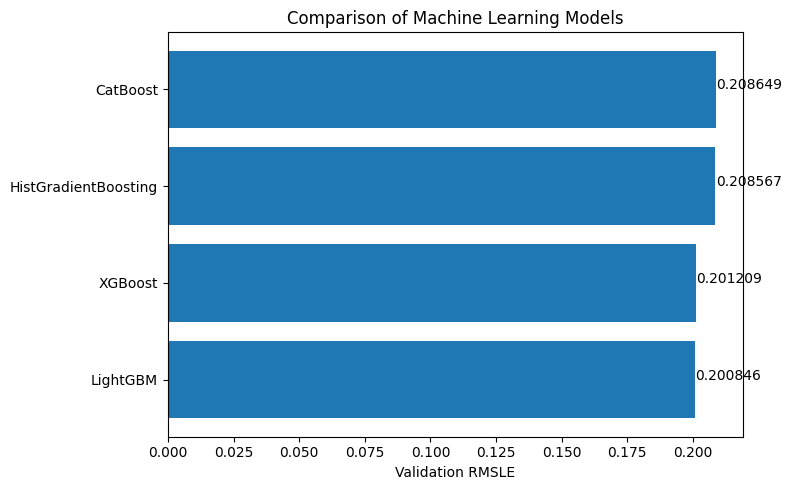

In [52]:
import matplotlib.pyplot as plt

comparison = model_comparison.sort_values("Validation RMSLE")

plt.figure(figsize=(8,5))

plt.barh(
    comparison["Model"],
    comparison["Validation RMSLE"]
)

plt.xlabel("Validation RMSLE")
plt.title("Comparison of Machine Learning Models")

for i, value in enumerate(comparison["Validation RMSLE"]):
    plt.text(value + 0.0002, i, f"{value:.6f}")

plt.tight_layout()
plt.show()

# Ensemble Comparison

In [53]:
import pandas as pd

ensemble_comparison = pd.DataFrame({
    "Ensemble Model": [
        "LightGBM + XGBoost",
        "LightGBM + XGBoost + CatBoost",
        "LightGBM + XGBoost + HistGradientBoosting",
        "LightGBM + XGBoost + CatBoost + HistGradientBoosting"
    ],
    "Validation RMSLE": [
        0.195614,
        0.194656,
        0.195615,
        0.194667
    ]
})

ensemble_comparison["Rank"] = (
    ensemble_comparison["Validation RMSLE"]
    .rank(method="dense")
    .astype(int)
)

ensemble_comparison = (
    ensemble_comparison
    .sort_values("Validation RMSLE")
    .reset_index(drop=True)
)

ensemble_comparison["Validation RMSLE"] = (
    ensemble_comparison["Validation RMSLE"].round(6)
)

ensemble_comparison

,Ensemble Model,Validation RMSLE,Rank
0,LightGBM + XGBoost + CatBoost,0.194656,1
1,LightGBM + XGBoost + CatBoost + HistGradientBo...,0.194667,2
2,LightGBM + XGBoost,0.195614,3
3,LightGBM + XGBoost + HistGradientBoosting,0.195615,4


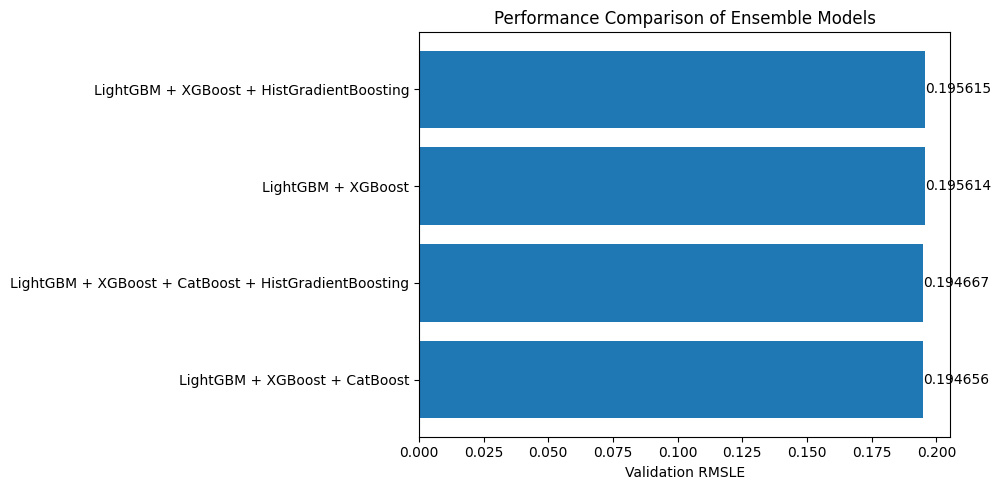

In [54]:
import matplotlib.pyplot as plt

comparison = ensemble_comparison.sort_values("Validation RMSLE")

plt.figure(figsize=(10,5))

plt.barh(
    comparison["Ensemble Model"],
    comparison["Validation RMSLE"]
)

plt.xlabel("Validation RMSLE")
plt.title("Performance Comparison of Ensemble Models")

for i, value in enumerate(comparison["Validation RMSLE"]):
    plt.text(value + 0.0001, i, f"{value:.6f}", va="center")

plt.tight_layout()
plt.show()

In [55]:
best_single = 0.2008458822168687

ensemble_comparison["Improvement"] = (
    best_single - ensemble_comparison["Validation RMSLE"]
)

ensemble_comparison

,Ensemble Model,Validation RMSLE,Rank,Improvement
0,LightGBM + XGBoost + CatBoost,0.194656,1,0.006190
1,LightGBM + XGBoost + CatBoost + HistGradientBo...,0.194667,2,0.006179
2,LightGBM + XGBoost,0.195614,3,0.005232
3,LightGBM + XGBoost + HistGradientBoosting,0.195615,4,0.005231


Text(0.5, 0, 'Improvement in RMSLE')

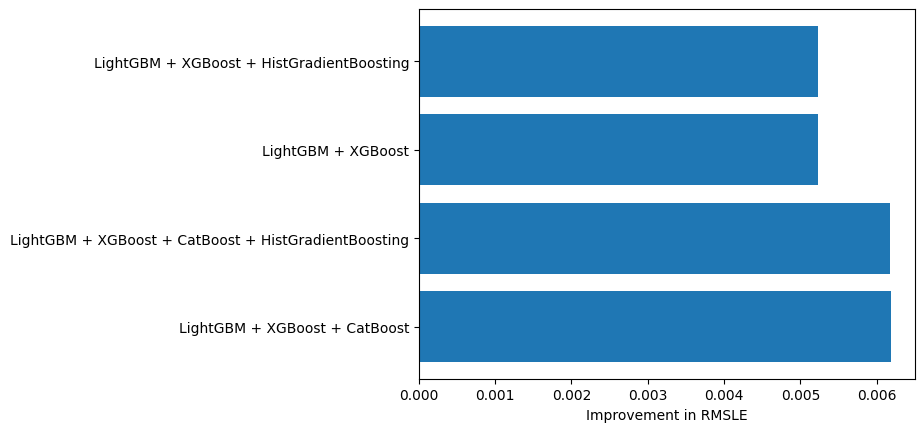

In [56]:
plt.barh(
    ensemble_comparison["Ensemble Model"],
    ensemble_comparison["Improvement"]
)

plt.xlabel("Improvement in RMSLE")

# Final full training and submission pipeline

In [57]:
#Final training and submission

X_full = X
y_full = y

In [58]:
# Original datasets (for LightGBM & CatBoost)
X_full_original = X_full.copy()
test = test.copy()

In [59]:
# ==========================================
# Final CatBoost Data
# ==========================================

X_full_cb = X_full.copy()
X_test_cb = test.copy()

# IMPORTANT: Recalculate using updated 59-feature dataset
numerical_cols_cb = X_full_cb.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols_cb = X_full_cb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical:", len(numerical_cols_cb))     # Expected: 16
print("Categorical:", len(categorical_cols_cb)) # Expected: 43
print("Total:", len(numerical_cols_cb) + len(categorical_cols_cb)) # 59

Numerical: 16
Categorical: 43
Total: 59


In [60]:
from sklearn.impute import SimpleImputer

# Numerical imputation
num_imputer_full = SimpleImputer(strategy="mean")

X_full_cb[numerical_cols_cb] = num_imputer_full.fit_transform(
    X_full_cb[numerical_cols_cb]
)

X_test_cb[numerical_cols_cb] = num_imputer_full.transform(
    X_test_cb[numerical_cols_cb]
)


# Categorical imputation
cat_imputer_full = SimpleImputer(strategy="most_frequent")

X_full_cb[categorical_cols_cb] = cat_imputer_full.fit_transform(
    X_full_cb[categorical_cols_cb]
)

X_test_cb[categorical_cols_cb] = cat_imputer_full.transform(
    X_test_cb[categorical_cols_cb]
)

In [61]:
# Log transform the full target

y_full_log = np.log1p(y_full)

# Get categorical features indices

cat_features_full = [
    X_full_cb.columns.get_loc(col)
    for col in categorical_cols
]

# Train final catboost model and fit

from catboost import CatBoostRegressor

cat_model_final = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=8,
    loss_function="RMSE",
    random_seed=42,
    verbose=100
)

cat_model_final.fit(
    X_full_cb,
    y_full_log,
    cat_features=cat_features_full
)

0:	learn: 0.6281236	total: 830ms	remaining: 13m 48s
100:	learn: 0.2460934	total: 1m 15s	remaining: 11m 8s
200:	learn: 0.2274998	total: 2m 31s	remaining: 10m 4s

[CV] END l2_regularization=0.005522117123602399, learning_rate=0.08339152856093507, max_bins=216, max_depth=None, max_iter=618, min_samples_leaf=42; total time=  32.2s
[CV] END l2_regularization=0.6232981268275579, learning_rate=0.03978082223673843, max_bins=247, max_depth=10, max_iter=606, min_samples_leaf=33; total time=  36.4s
[CV] END l2_regularization=0.6232981268275579, learning_rate=0.03978082223673843, max_bins=247, max_depth=10, max_iter=606, min_samples_leaf=33; total time=  36.0s
[CV] END l2_regularization=0.6659223566174967, learning_rate=0.06321680089369544, max_bins=221, max_depth=10, max_iter=746, min_samples_leaf=10; total time=  38.1s

[CV] END l2_regularization=0.6059599747810114, learning_rate=0.0933670790662014, max_bins=240, max_depth=None, max_iter=334, min_samples_leaf=18; total time=  19.4s
[CV] END l2_r

CatBoostRegressor(depth=8, iterations=1000, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=100)

In [62]:
#Final LightGBM data 

X_full_lgb = X_full.copy()
X_test_lgb = test.copy()

numerical_cols_lgb = X_full_lgb.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols_lgb = X_full_lgb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

In [63]:
#Impute Missing values

from sklearn.impute import SimpleImputer

imputer_lgb = SimpleImputer(strategy="median")

X_full_lgb[numerical_cols_lgb] = imputer_lgb.fit_transform(
    X_full_lgb[numerical_cols_lgb]
)

X_test_lgb[numerical_cols_lgb] = imputer_lgb.transform(
    X_test_lgb[numerical_cols_lgb]
)

In [64]:
#Convert Categorical features

for col in categorical_cols_lgb:

    X_full_lgb[col] = X_full_lgb[col].astype("category")

    X_test_lgb[col] = pd.Categorical(
        X_test_lgb[col],
        categories=X_full_lgb[col].cat.categories
    )

In [65]:
#Train and Fit final LightGBM

from lightgbm import LGBMRegressor

lgb_model_final = LGBMRegressor(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=127,
    feature_fraction=0.8,
    random_state=42
)

lgb_model_final.fit(
    X_full_lgb,
    y_full_log
)

LGBMRegressor(feature_fraction=0.8, learning_rate=0.05, max_depth=8,
              n_estimators=3000, num_leaves=127, random_state=42)

In [66]:
# Transform the FULL training data
X_train_full_hgb = preprocessor_hgb.fit_transform(X_full, y_full)

# Transform the Kaggle test data
X_test_hgb = preprocessor_hgb.transform(test)

In [67]:
#Train 

from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=1000,
    max_depth=8,
    max_leaf_nodes=255,
    random_state=42
)

hgb_model.fit(X_train_full_hgb, np.log1p(y))

HistGradientBoostingRegressor(learning_rate=0.05, max_depth=8, max_iter=1000,
                              max_leaf_nodes=255, random_state=42)

In [68]:
#HGB Final Predictions
# Predict in log space
hgb_pred_log = hgb_model.predict(X_test_hgb)

# Convert back
hgb_pred = np.expm1(hgb_pred_log)

# Safety
hgb_pred = np.maximum(hgb_pred, 0)

In [69]:
numerical_cols = X_full.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X_full.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print(len(numerical_cols))
print(len(categorical_cols))
print(len(numerical_cols) + len(categorical_cols))

16
43
59


In [70]:
#XGBoost Final Preprocessing pipeline
preprocessor_xgb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_hgb, numerical_cols),
        ("cat", categorical_transformer_hgb, categorical_cols)
    ]
)

X_full_xgb = preprocessor_xgb.fit_transform(X_full)
X_test_xgb = preprocessor_xgb.transform(test)

print(X_full_xgb.shape)
print(X_test_xgb.shape)

(138701, 59)
(15000, 59)


In [71]:
#Create XGBoost model and Fit
from xgboost import XGBRegressor
import numpy as np

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    learning_rate=0.03,
    n_estimators=7000,
    max_depth=8,
    subsample=0.9,
    colsample_bytree=0.8,
    min_child_weight=1,
    gamma=0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_full_xgb,
    np.log1p(y)
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=1, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=7000,
             n_jobs=-1, num_parallel_tree=None, ...)

In [72]:
#Predict using fitted XGB
# Predict in log space
xgb_pred_log = xgb_model.predict(X_test_xgb)

# Convert back
xgb_pred = np.expm1(xgb_pred_log)

# Prevent negative predictions
xgb_pred = np.maximum(xgb_pred, 0)

In [73]:
#Catboost Final Predictions

# Predict in log space
cat_pred_log = cat_model_final.predict(X_test_cb)

# Convert back to original scale
cat_pred = np.expm1(cat_pred_log)

# Safety
cat_pred = np.maximum(cat_pred, 0)



In [74]:
#LightGBM Final Predictions

# Predict in log space
lgb_pred_log = lgb_model_final.predict(X_test_lgb)

# Convert back to original scale
lgb_pred = np.expm1(lgb_pred_log)

# Safety
lgb_pred = np.maximum(lgb_pred, 0)

In [75]:
#Ensemble

ensemble_pred = (
    0.40 * lgb_pred +
    0.37 * xgb_pred +
    0.18 * cat_pred +
    0.05 * hgb_pred
)


In [76]:
submission = sample_submission.copy()

submission["TargetValue"] = ensemble_pred

submission.head()

,TransactionID,TargetValue
0,1139307,67091.320368
1,1139419,77554.234263
2,1139482,32189.936495
3,1139522,20339.191022
4,1139684,12959.956747


In [77]:
submission.to_csv("submission.csv", index=False)

#MILESTONE 1

#Q1:
print(train)
print(test)

#Q2:
set(train.columns)-set(test.columns)

#Q3:
train.dtypes

#Q4:
missing = train.isnull().sum()

threshold = 124800  # 90% of 138,701 ≈ 124,831

missing[missing > threshold]

#Q5:

print(train['OperationalHoursMeter'].isnull().sum())

#Q6:

print(train['TargetValue'].median())

#Q7:

print(train['ManufactureYear'].mode())

#Q8:

print(train['TransactionDate'].min())

#Q9:

print(train['Spec_BaseClass'].nunique())

#Q10:

train['RegionCode'].value_counts()

#Q11:

print(train[train['RegionCode'] == 'Florida']['TargetValue'].mean())

#Q12:

print(train['UtilizationTier'].value_counts())

#Q13:

print(train['OperationalHoursMeter'].corr(train['TargetValue']))

#Q14:

train['FunctionalClassification'].value_counts()

#MILESTONE 2

import pandas as pd
import numpy as np

# Convert TransactionDate to datetime
train["TransactionDate"] = pd.to_datetime(train["TransactionDate"])

# 1. TransactionYear
train["TransactionYear"] = train["TransactionDate"].dt.year

# 2. TransactionQuarter
train["TransactionQuarter"] = train["TransactionDate"].dt.quarter

# 3. AssetAge
train["AssetAge"] = train["TransactionYear"] - train["ManufactureYear"]

# 4. DescriptorLength
train["DescriptorLength"] = (
    train["Spec_FullDescriptor"]
    .fillna("")
    .str.len()
)

# 5. HasOperationalHours
train["HasOperationalHours"] = (
    train["OperationalHoursMeter"]
    .notna()
    .astype(int)
)

# 6. HasVariantModifier
train["HasVariantModifier"] = (
    train["Spec_VariantModifier"]
    .notna()
    .astype(int)
)

# Q1
print("Q1:")
print(train["AssetAge"].value_counts().head())

# Q2
print("\nQ2:")
print(train.groupby("TransactionQuarter")["TargetValue"].mean())

# Q3
print("\nQ3:")
print(train["DescriptorLength"].max())

# Q4
print("\nQ4:")
print(train["HasOperationalHours"].sum())

# Q5
print("\nQ5:")
percentage = train["HasVariantModifier"].mean() * 100
print(percentage)

# Q6
print("\nQ6:")
print(round(train["ManufactureYear"].mean(), 2))

print(train.head())
count = sum(
    col.startswith(("RegionCode_", "CabinType_", "UtilizationTier_"))
    for col in train.columns
)

print(count)

features = [
    "ManufactureYear",
    "OperationalHoursMeter",
    "AssetID",
    "ProductConfigID"
]

print(train[features + ["TargetValue"]].corr(numeric_only=True)["TargetValue"])

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Numerical features to preprocess
num_cols = [
    "ManufactureYear",
    "OperationalHoursMeter",
    "AssetAge"
]

# Mean imputation
imputer = SimpleImputer(strategy="mean")
train[num_cols] = imputer.fit_transform(train[num_cols])

# Standard Scaling
scaler = StandardScaler()
train[num_cols] = scaler.fit_transform(train[num_cols])

# Features and target
X = train.drop(columns=["TargetValue"])
y = train["TargetValue"]

# Train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

features = ["ManufactureYear", "AssetAge"]

X = train[features]
y = train["TargetValue"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_val)

print("R²:", r2_score(y_val, pred))

#MILESTONE 3

#1.
train["TransactionYear"].mode()
#2. Median
#3. 
missing_percent = train.isnull().mean() * 100
cols_to_drop = missing_percent[missing_percent > 80]
print(cols_to_drop)
print("Columns dropped:", len(cols_to_drop))
#4. 
train["CabinType"].isnull().sum()

#MILESTONE 3 CONTD

#5.
import numpy as np

temp = train.copy()

temp["HoursPerYear"] = (
    temp["OperationalHoursMeter"] /
    temp["AssetAge"]
)

temp["HoursPerYear"].replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

print(temp["HoursPerYear"].median())

#6.
temp = train.copy()

temp.loc[
    temp["ManufactureYear"].isin([1000, 1001]),
    "ManufactureYear"
] = np.nan

temp["AssetAge"] = (
    temp["TransactionYear"] -
    temp["ManufactureYear"]
)

print(temp["AssetAge"].median())

#11.
import numpy as np

print(np.log1p(train["TargetValue"]).std())